# Proyecto Final ML - Análisis Exploratorio de Datos (EDA)
### Predicción del éxito académico en educación superior

En este notebook se realiza un análisis exploratorio completo del dataset de rendimiento de estudiantes. 
El objetivo es entender los datos antes de entrar en los modelos.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')   # silencio los warnings para que el notebook quede limpio

# configuración visual
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# colores consistentes para todo el proyecto
COLORES = {'abandono': '#e74c3c', 'matriculado': '#f39c12', 'graduado': '#2ecc71'}
ORDEN = ['abandono', 'matriculado', 'graduado']
SEED = 42   # fijo semilla para reproducibilidad

print("Todo importado correctamente")


Todo importado correctamente


## 1. Carga y primera inspección de los datos


In [2]:
df = pd.read_csv('rendimiento_estudiantes.csv', sep=';')
print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()


El dataset tiene 4424 filas y 37 columnas


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


### 1.1. Diccionario de variables por bloques

El enunciado presenta las variables agrupadas en bloques temáticos y mantener esa estructura me ayuda a razonar mejor el resto del proyecto (qué entra en cada tarea, qué riesgo de leakage tiene cada variable, etc.). Antes de mirar estadísticas dejo definidos esos bloques de forma explícita, porque luego los voy a reutilizar en clasificación, regresión y clustering.

Los bloques que uso son los mismos que describe el enunciado: demográficas, acceso y contexto académico previo, socioeconómicas y administrativas, macroeconómicas, rendimiento 1er semestre y rendimiento 2º semestre. Marco también las variables que son *tardías* (2º semestre), porque son las que no deben entrar en regresión como predictoras y las que condicionan la lectura de cualquier modelo de clasificación en clave de "intervención temprana".

In [3]:
# diccionario de variables por bloques temáticos, siguiendo el enunciado
# lo dejo aquí al principio porque se reutiliza en todos los notebooks posteriores
BLOQUES = {
    'demograficas': [
        'edad_al_matricularse', 'genero', 'estado_civil',
        'nacionalidad', 'internacional', 'desplazado',
    ],
    'acceso': [
        'modo_solicitud', 'orden_solicitud', 'curso',
        'asistencia_diurna_vespertina', 'cualificacion_previa',
        'nota_cualificacion_previa', 'nota_admision',
        'cualificacion_madre', 'cualificacion_padre',
        'ocupacion_madre', 'ocupacion_padre',
    ],
    'socioeconomicas': [
        'becado', 'deudor', 'matricula_al_dia',
        'necesidades_educativas_especiales',
    ],
    'macroeconomicas': [
        'tasa_desempleo', 'tasa_inflacion', 'pib',
    ],
    'rendimiento_1sem': [
        'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas',
        'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas',
        'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion',
    ],
    'rendimiento_2sem': [
        'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas',
        'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas',
        'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion',
    ],
}

# todas las variables del dataset deberían caer en algún bloque
# (menos 'objetivo', que es la target)
todas_bloques = [v for lista in BLOQUES.values() for v in lista]
faltan = [c for c in df.columns if c not in todas_bloques and c != 'objetivo']
sobran = [v for v in todas_bloques if v not in df.columns]
print(f'Variables asignadas a un bloque: {len(todas_bloques)}')
print(f'Columnas del dataset sin asignar (deberia ser 0, sin contar objetivo): {faltan}')
print(f'Variables en bloques pero no en el dataset (deberia ser 0): {sobran}')

# las variables del 2do semestre las marco aparte porque son las tardías
VARS_TARDIAS = BLOQUES['rendimiento_2sem']
print(f'\nVariables tardías (2º semestre): {VARS_TARDIAS}')

Variables asignadas a un bloque: 36
Columnas del dataset sin asignar (deberia ser 0, sin contar objetivo): []
Variables en bloques pero no en el dataset (deberia ser 0): []

Variables tardías (2º semestre): ['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion']


In [4]:
# tipos de datos y si hay nulos
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   estado_civil                       4424 non-null   object 
 1   modo_solicitud                     4424 non-null   object 
 2   orden_solicitud                    4424 non-null   int64  
 3   curso                              4424 non-null   object 
 4   asistencia_diurna_vespertina       4424 non-null   object 
 5   cualificacion_previa               4424 non-null   object 
 6   nota_cualificacion_previa          4424 non-null   float64
 7   nacionalidad                       4424 non-null   object 
 8   cualificacion_madre                4424 non-null   object 
 9   cualificacion_padre                4424 non-null   object 
 10  ocupacion_madre                    4424 non-null   object 
 11  ocupacion_padre                    4424 non-null   objec

In [5]:
# hay ningún valor nulo en todo el dataset
print(f"Valores nulos totales: {df.isnull().sum().sum()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")


Valores nulos totales: 0
Filas duplicadas: 0


In [6]:
# además de los bloques temáticos necesito listas por tipo (numérico/categórico)
# para los gráficos y cálculos de estadística descriptiva
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# la variable objetivo la quito de las categóricas porque la trato aparte
cat_cols.remove('objetivo')

print(f'Variables categoricas ({len(cat_cols)}):')
for c in cat_cols: print(f'  - {c}')
print(f'\nVariables numericas ({len(num_cols)}):')
for c in num_cols: print(f'  - {c}')
print(f"\nVariable objetivo: 'objetivo' (3 clases)")

# algunas numéricas son en verdad ordinales de baja cardinalidad
# (como orden_solicitud, asignaturas_Xsem_*). En el EDA las trato como numéricas
# por simplicidad pero en los modelos posteriores volveré sobre
# esta decisión variable por variable.

Variables categoricas (17):
  - estado_civil
  - modo_solicitud
  - curso
  - asistencia_diurna_vespertina
  - cualificacion_previa
  - nacionalidad
  - cualificacion_madre
  - cualificacion_padre
  - ocupacion_madre
  - ocupacion_padre
  - desplazado
  - necesidades_educativas_especiales
  - deudor
  - matricula_al_dia
  - genero
  - becado
  - internacional

Variables numericas (19):
  - orden_solicitud
  - nota_cualificacion_previa
  - nota_admision
  - edad_al_matricularse
  - asignaturas_1sem_convalidadas
  - asignaturas_1sem_matriculadas
  - asignaturas_1sem_evaluadas
  - asignaturas_1sem_aprobadas
  - nota_media_1sem
  - asignaturas_1sem_sin_evaluacion
  - asignaturas_2sem_convalidadas
  - asignaturas_2sem_matriculadas
  - asignaturas_2sem_evaluadas
  - asignaturas_2sem_aprobadas
  - nota_media_2sem
  - asignaturas_2sem_sin_evaluacion
  - tasa_desempleo
  - tasa_inflacion
  - pib

Variable objetivo: 'objetivo' (3 clases)


## 2. Análisis de la variable objetivo

Lo primero que quiero ver es como se reparten los estudiantes entre las tres clases. 
Esto es importante porque si hay desbalanceo habrá que tenerlo en cuenta luego en clasificación.


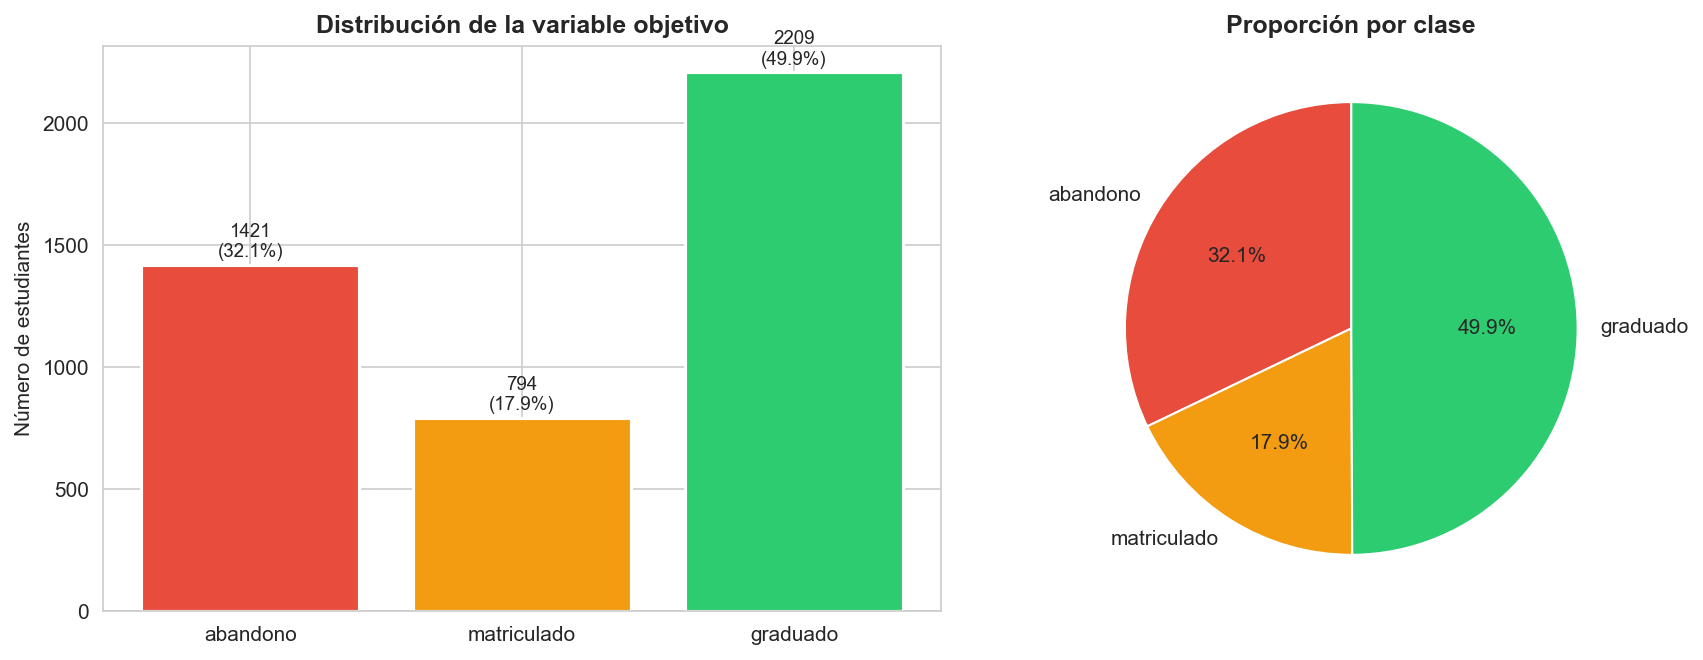

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts = df['objetivo'].value_counts().reindex(ORDEN)

# gráfico de barras
bars = axes[0].bar(ORDEN, counts.values, color=[COLORES[c] for c in ORDEN], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)
axes[0].set_title('Distribución de la variable objetivo', fontweight='bold')
axes[0].set_ylabel('Número de estudiantes')

# gráfico circular
axes[1].pie(counts.values, labels=ORDEN, colors=[COLORES[c] for c in ORDEN],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 10})
axes[1].set_title('Proporción por clase', fontweight='bold')

plt.tight_layout()
plt.show()


In [8]:
# resumen numérico del desbalanceo y baselines
print('Distribución de la variable objetivo:')
print('-' * 55)
for clase in ORDEN:
    n = (df['objetivo'] == clase).sum() # número de estudiantes en esa clase
    pct = n / len(df) * 100             # porcentaje respecto al total  
    print(f'  {clase:15s}: {n:4d} estudiantes ({pct:.1f}%)')
print(f"\nRatio mayor/menor clase: {counts.max()/counts.min():.2f}x")

# si siempre predijera la clase mayoritaria (graduado) ¿qué accuracy y F1 sacaría? 
# así puedo saber qué mejora tiene que aportar un modelo para ser útil
from sklearn.metrics import accuracy_score, f1_score
mayoritaria = counts.idxmax()  
pred_trivial = [mayoritaria] * len(df) 
acc_trivial = accuracy_score(df['objetivo'], pred_trivial)
f1_macro_trivial = f1_score(df['objetivo'], pred_trivial, average='macro')
f1_weighted_trivial = f1_score(df['objetivo'], pred_trivial, average='weighted')
print('\nBaseline trivial (predecir siempre la clase mayoritaria):')
print(f'  - accuracy:    {acc_trivial:.4f}')
print(f'  - F1 macro:    {f1_macro_trivial:.4f}  <- el que usaré como referencia principal')
print(f'  - F1 weighted: {f1_weighted_trivial:.4f}')

# Uso F1 como métrica ppal en clasificación porque accuracy engaña en clases desbalanceadas
# F1 macro penaliza ignorar a la minoritaria y en este problema de abandono me importa detectarlo


Distribución de la variable objetivo:
-------------------------------------------------------
  abandono       : 1421 estudiantes (32.1%)
  matriculado    :  794 estudiantes (17.9%)
  graduado       : 2209 estudiantes (49.9%)

Ratio mayor/menor clase: 2.78x

Baseline trivial (predecir siempre la clase mayoritaria):
  - accuracy:    0.4993
  - F1 macro:    0.2220  <- el que usaré como referencia principal
  - F1 weighted: 0.3326


## 3. Estadísticas descriptivas de variables numéricas


In [9]:
# estadísticas básicas de todas las variables numéricas
df[num_cols].describe().round(2).T  # transpuesto para que se vea mejor


,count,mean,std,min,25%,50%,75%,max
orden_solicitud,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
nota_cualificacion_previa,4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
nota_admision,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
edad_al_matricularse,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
asignaturas_1sem_convalidadas,4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
asignaturas_1sem_matriculadas,4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
asignaturas_1sem_evaluadas,4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
asignaturas_1sem_aprobadas,4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
nota_media_1sem,4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
asignaturas_1sem_sin_evaluacion,4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


In [10]:
# - edad_al_matricularse: media es 23 pero hay gente de hasta 70 años (pueden ser outliers)
# - asignaturas_Xsem_convalidadas: la mayoría es 0 (son excepciones)
# - las notas medias van de 0 a 19 con mediana alrededor de 12

# veo los outliers de edad
print("Distribución de edad:")
print(df['edad_al_matricularse'].describe())
print(f"\nEstudiantes mayores de 40: {(df['edad_al_matricularse'] > 40).sum()}")
print(f"Estudiantes mayores de 50: {(df['edad_al_matricularse'] > 50).sum()}")

# mantengo estudiantes mayores en el dataset. No son errores de captura (su presencia es informativa)
# edad al matricularse está asociada a trayectoria académica

Distribución de edad:
count    4424.000000
mean       23.265145
std         7.587816
min        17.000000
25%        19.000000
50%        20.000000
75%        25.000000
max        70.000000
Name: edad_al_matricularse, dtype: float64

Estudiantes mayores de 40: 225
Estudiantes mayores de 50: 43


## 4. Distribuciones de variables numéricas por clase

Aquí miro cómo se distribuye cada variable numérica clave separando por clase objetivo. Esto ya me da una primera idea de qué variables van a ser útiles para clasificar.

> **Nota metodológica.** En esta sección aparecen dos tipos de variables muy distintos:
> - **tempranas**: acceso (nota de admisión, nota de cualificación previa) + 1er semestre (nota media 1sem, asignaturas 1sem aprobadas) + perfil (edad).
> - **tardías** (2º semestre): `nota_media_2sem`, `asignaturas_2sem_aprobadas`.
>
> Las tardías son muy informativas para describir el fenómeno del abandono/graduación, pero conviene separarlas mentalmente: no se usarán como predictoras en la regresión (porque filtrarían información del target) y no sostienen una lectura de "intervención temprana" en clasificación.

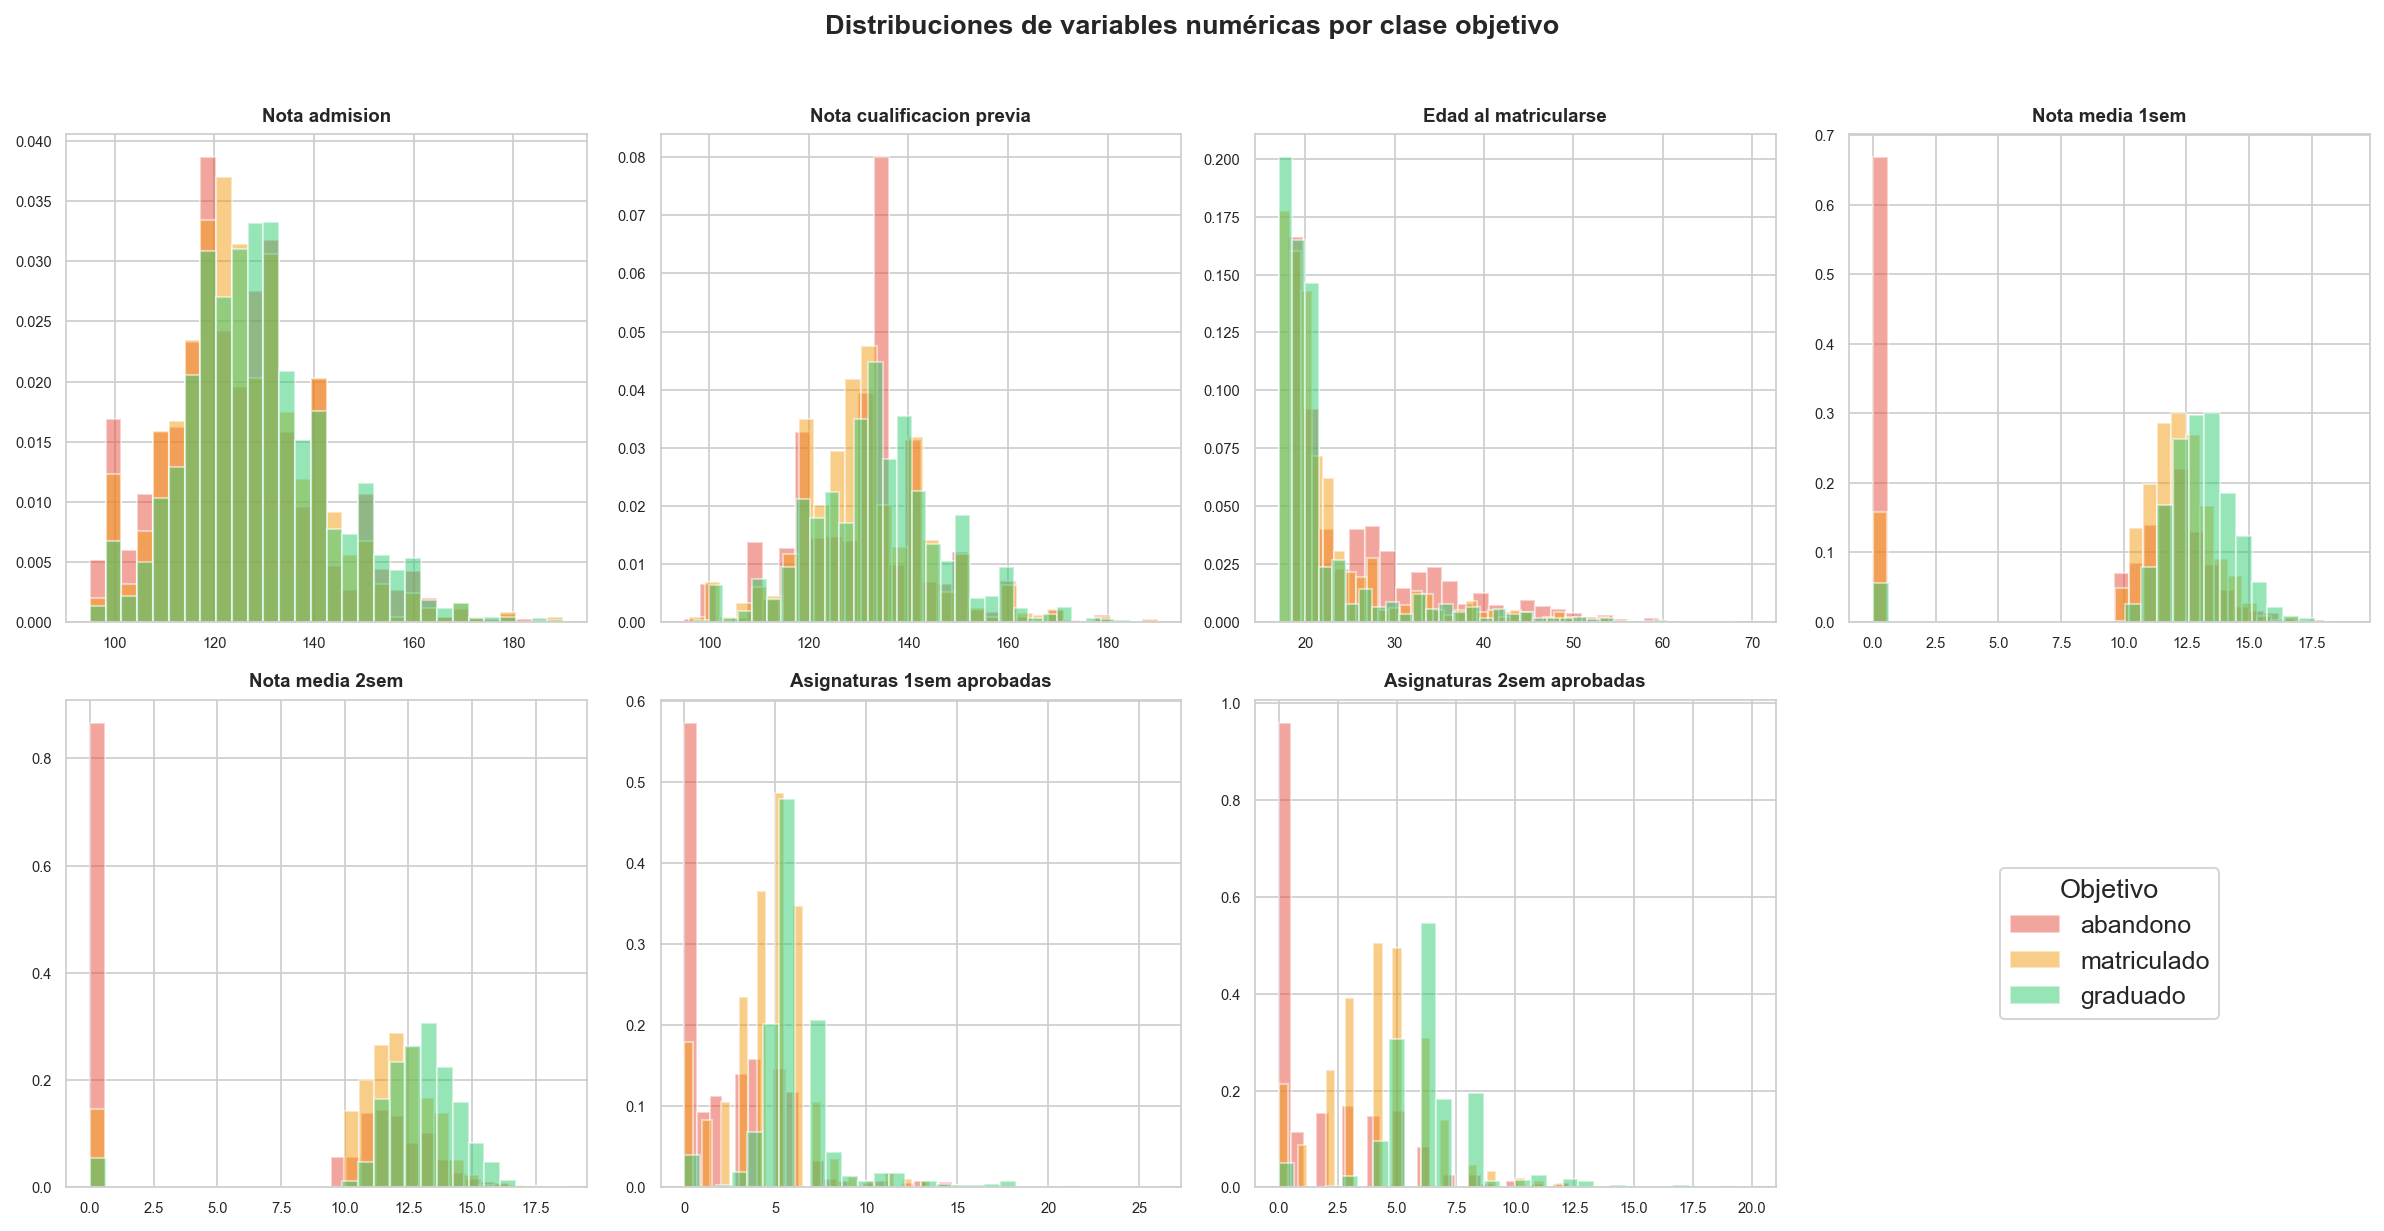

In [11]:
vars_clave = ['nota_admision', 'nota_cualificacion_previa', 'edad_al_matricularse',
              'nota_media_1sem', 'nota_media_2sem',
              'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(vars_clave):
    for cat in ORDEN:
        subset = df[df['objetivo'] == cat][var]
        axes[i].hist(subset, bins=30, alpha=0.5, color=COLORES[cat], label=cat, density=True)
    axes[i].set_title(var.replace('_', ' ').capitalize(), fontsize=9, fontweight='bold')
    axes[i].tick_params(labelsize=7)

# la última celda la uso para la leyenda
axes[-1].axis('off')
axes[-1].legend(*axes[0].get_legend_handles_labels(), loc='center', fontsize=12,
                title='Objetivo', title_fontsize=13)

plt.suptitle('Distribuciones de variables numéricas por clase objetivo', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


## 5. Boxplots de notas por clase

Los boxplots son muy útiles para ver de un vistazo las diferencias entre grupos. 
Aqui se comparan las tres notas principales.


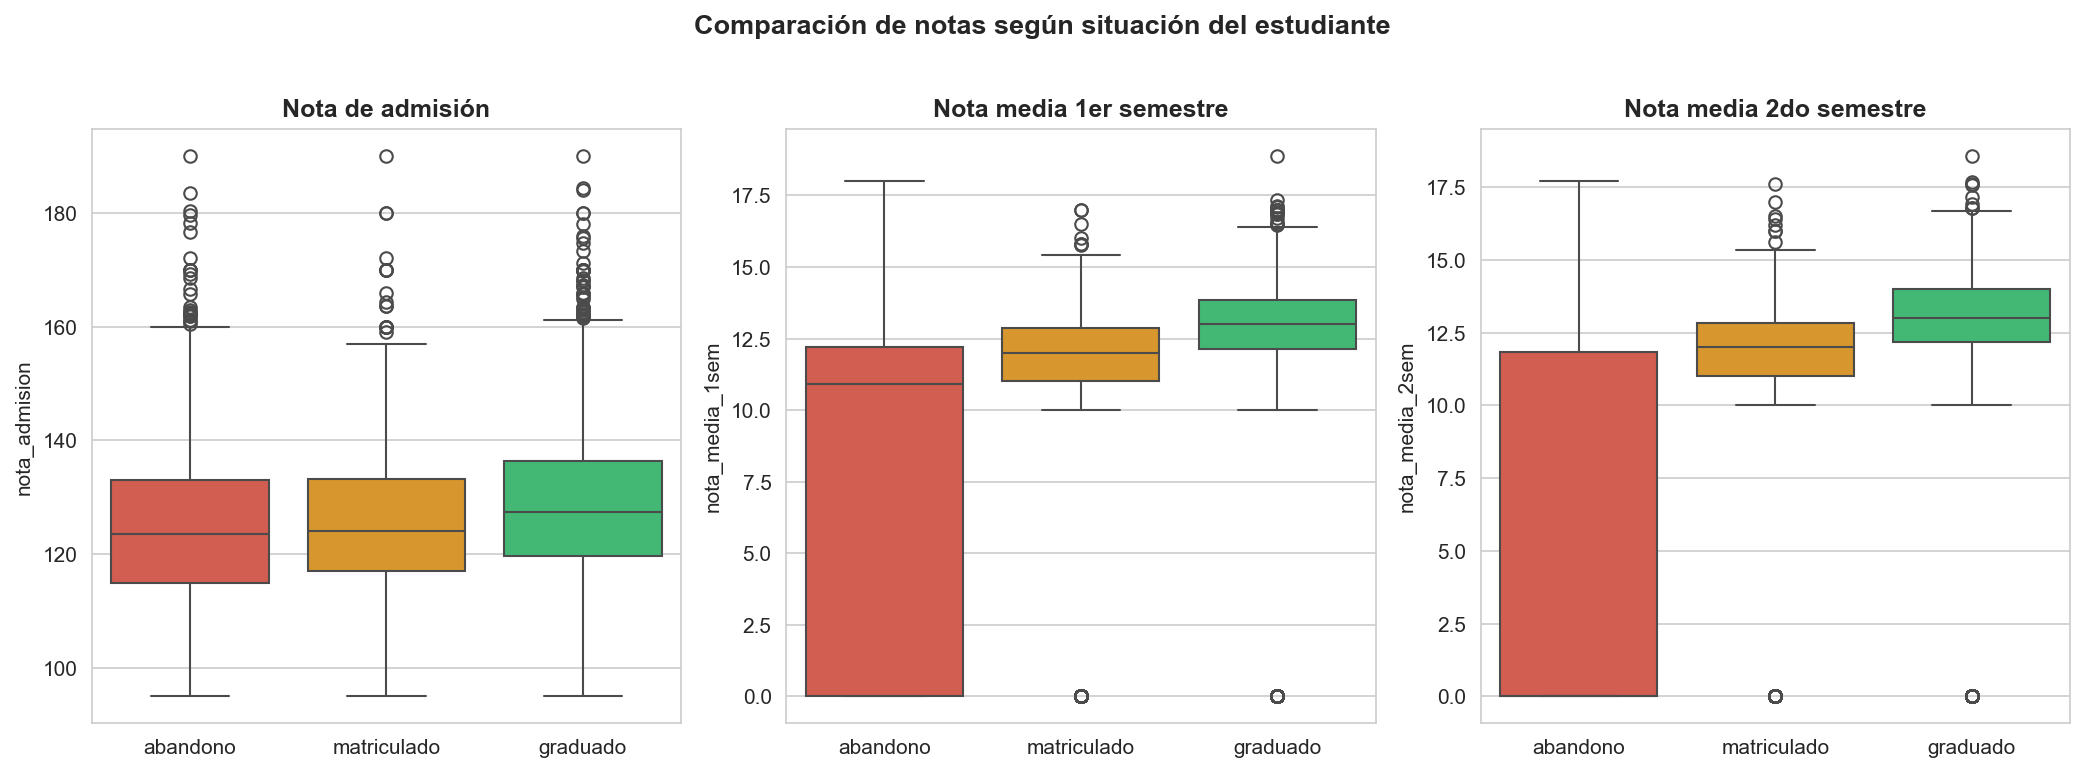

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, var, titulo in zip(axes,
    ['nota_admision', 'nota_media_1sem', 'nota_media_2sem'],
    ['Nota de admisión', 'Nota media 1er semestre', 'Nota media 2do semestre']):
    sns.boxplot(data=df, x='objetivo', y=var, order=ORDEN,
                hue='objetivo', hue_order=ORDEN, palette=COLORES, ax=ax, legend=False)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Comparación de notas según situación del estudiante', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


In [13]:
# la diferencia más clara esta en las notas de 1er y 2do semestre
# los graduados tienen notas claramente mas altas
# los de abandono tienen muchos valores en 0 porque no se presentan 

print("Nota media 1er semestre por clase:")
print(df.groupby('objetivo')['nota_media_1sem'].agg(['mean', 'median', 'std']).reindex(ORDEN).round(2))
print()
print("Nota media 2do semestre por clase:")
print(df.groupby('objetivo')['nota_media_2sem'].agg(['mean', 'median', 'std']).reindex(ORDEN).round(2))


Nota media 1er semestre por clase:
              mean  median   std
objetivo                        
abandono      7.26   10.93  6.03
matriculado  11.13   12.00  3.68
graduado     12.64   13.00  2.70

Nota media 2do semestre por clase:
              mean  median   std
objetivo                        
abandono      5.90     0.0  6.12
matriculado  11.12    12.0  3.60
graduado     12.70    13.0  2.69


## 6. Matriz de correlación

Miro las correlaciones entre todas las variables numéricas. Me interesa detectar:
- Variables muy correlacionadas entre sí (posible redundancia)
- Variables que se correlacionan fuerte con la nota del 2do semestre (para regresión)


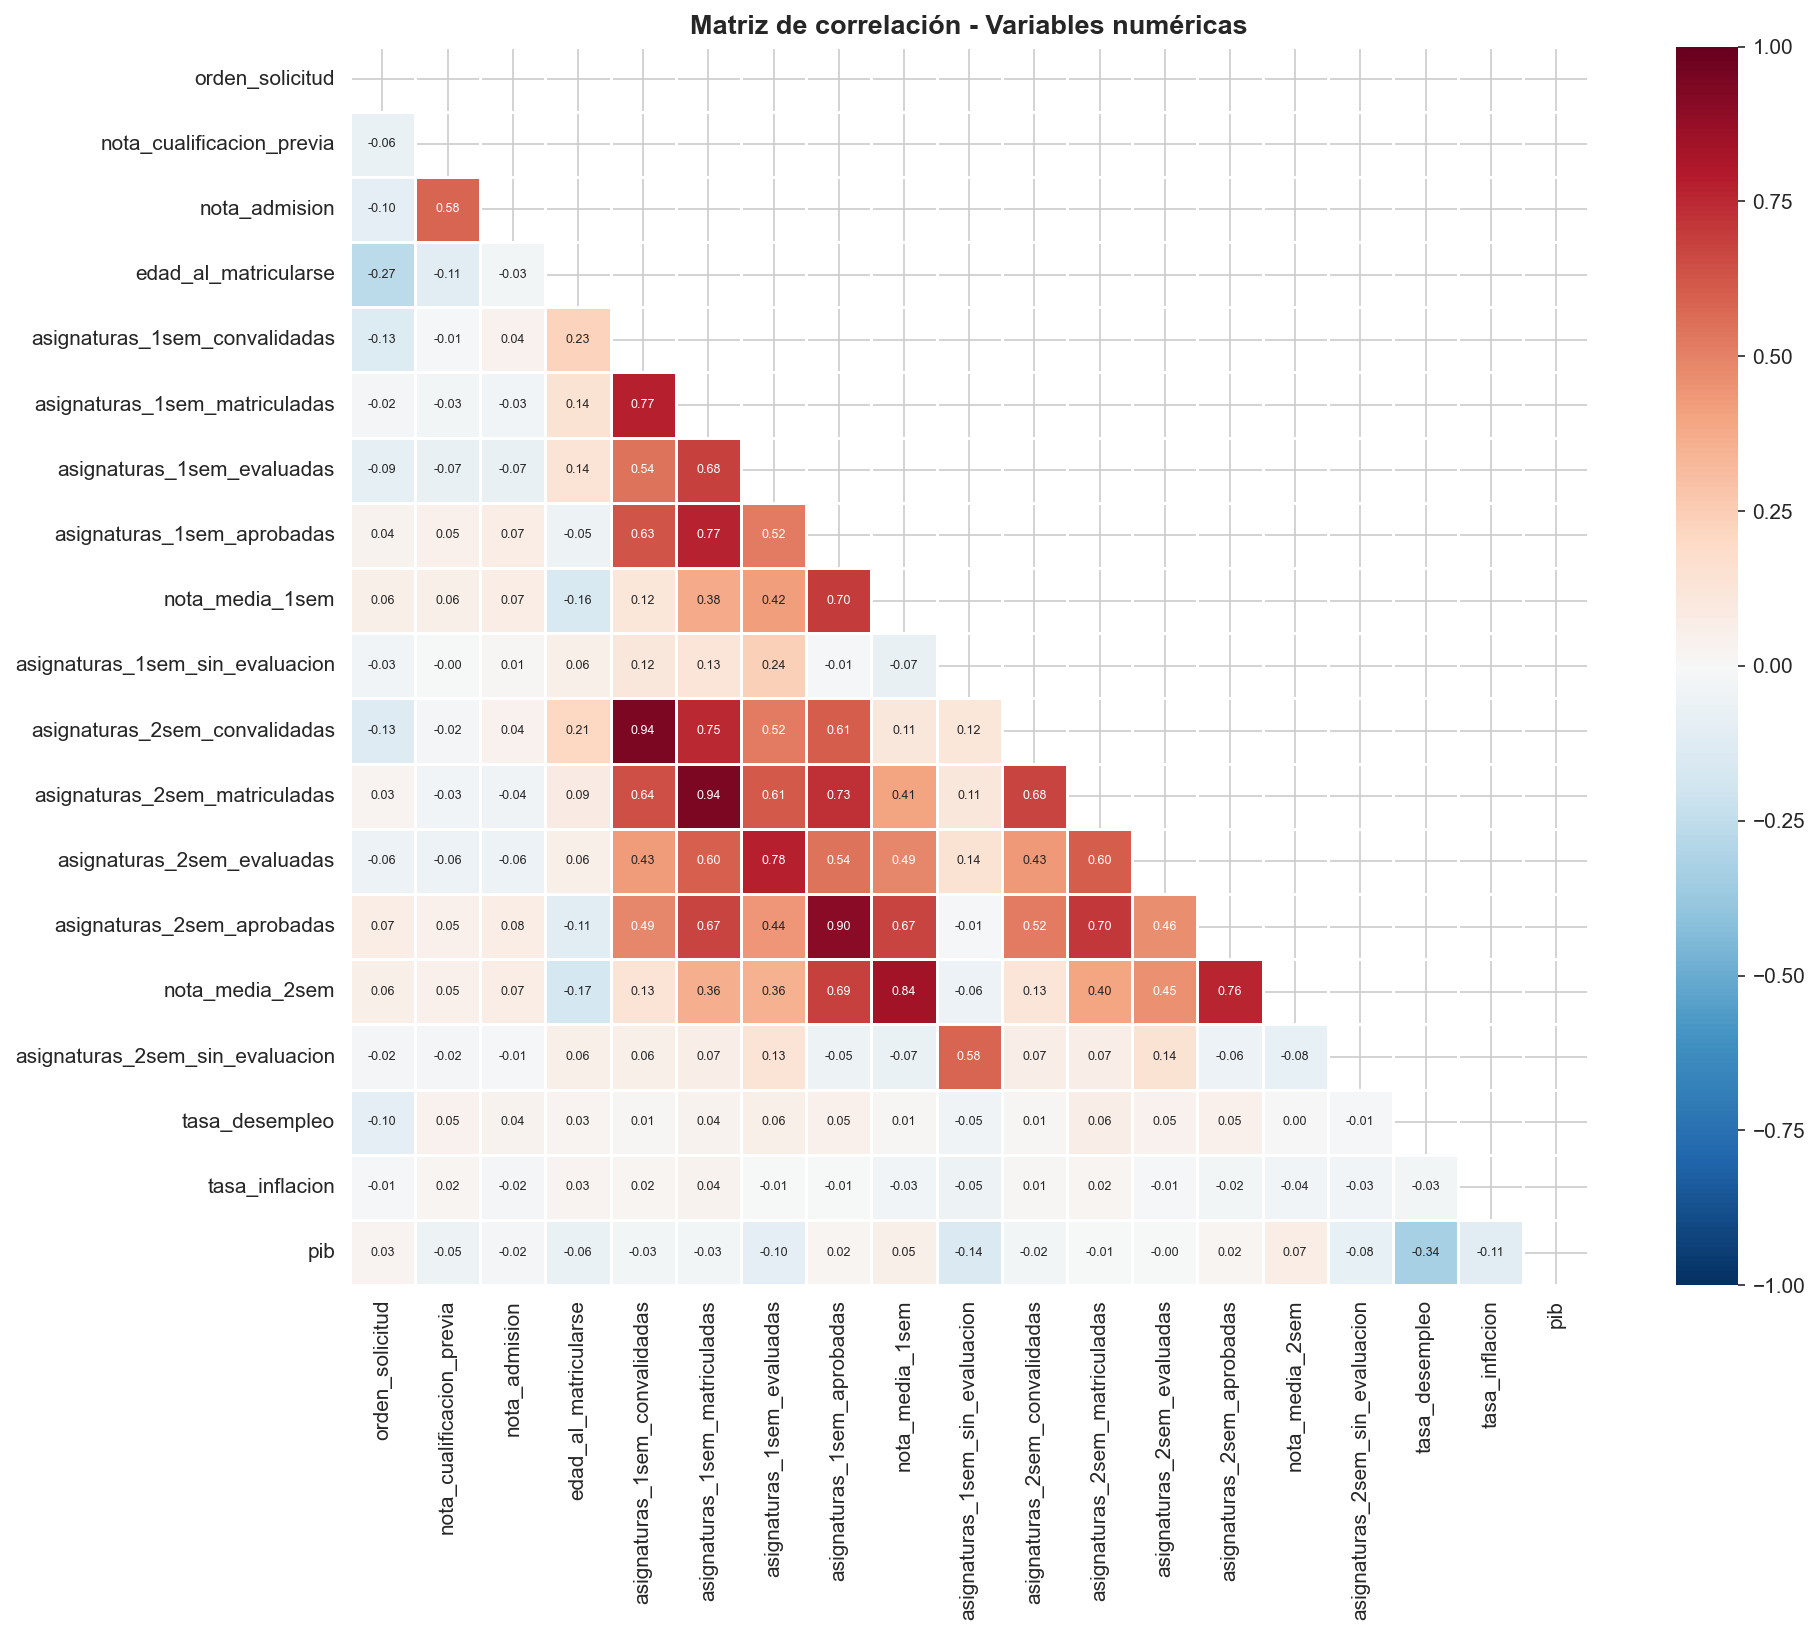

In [14]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))  # solo muestro la mitad superior para evitar duplicados
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, annot=True, fmt='.2f',
            square=True, linewidths=0.5, ax=ax, annot_kws={'size': 6},
            vmin=-1, vmax=1)    
ax.set_title('Matriz de correlación - Variables numéricas', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()


In [15]:
# correlaciones más fuertes con nota_media_2sem (el target de regresión)
corr_target = corr['nota_media_2sem'].drop('nota_media_2sem').sort_values(ascending=False)
print("Correlaciones con nota_media_2sem (target de regresión):")
print("-" * 50)
for var, val in corr_target.items():
    flag = " <-- ojo, data leakage" if '2sem' in var and var != 'nota_media_2sem' else ""
    print(f"  {var:45s}: {val:+.3f}{flag}")


Correlaciones con nota_media_2sem (target de regresión):
--------------------------------------------------
  nota_media_1sem                              : +0.837
  asignaturas_2sem_aprobadas                   : +0.761 <-- ojo, data leakage
  asignaturas_1sem_aprobadas                   : +0.686
  asignaturas_2sem_evaluadas                   : +0.453 <-- ojo, data leakage
  asignaturas_2sem_matriculadas                : +0.395 <-- ojo, data leakage
  asignaturas_1sem_matriculadas                : +0.362
  asignaturas_1sem_evaluadas                   : +0.355
  asignaturas_1sem_convalidadas                : +0.133
  asignaturas_2sem_convalidadas                : +0.130 <-- ojo, data leakage
  nota_admision                                : +0.074
  pib                                          : +0.071
  orden_solicitud                              : +0.056
  nota_cualificacion_previa                    : +0.053
  tasa_desempleo                               : +0.001
  tasa_inflacion    

## 7. Variables categóricas binarias vs objetivo

Cada barra es el % de abandono/matriculado/graduado dentro de cada grupo.

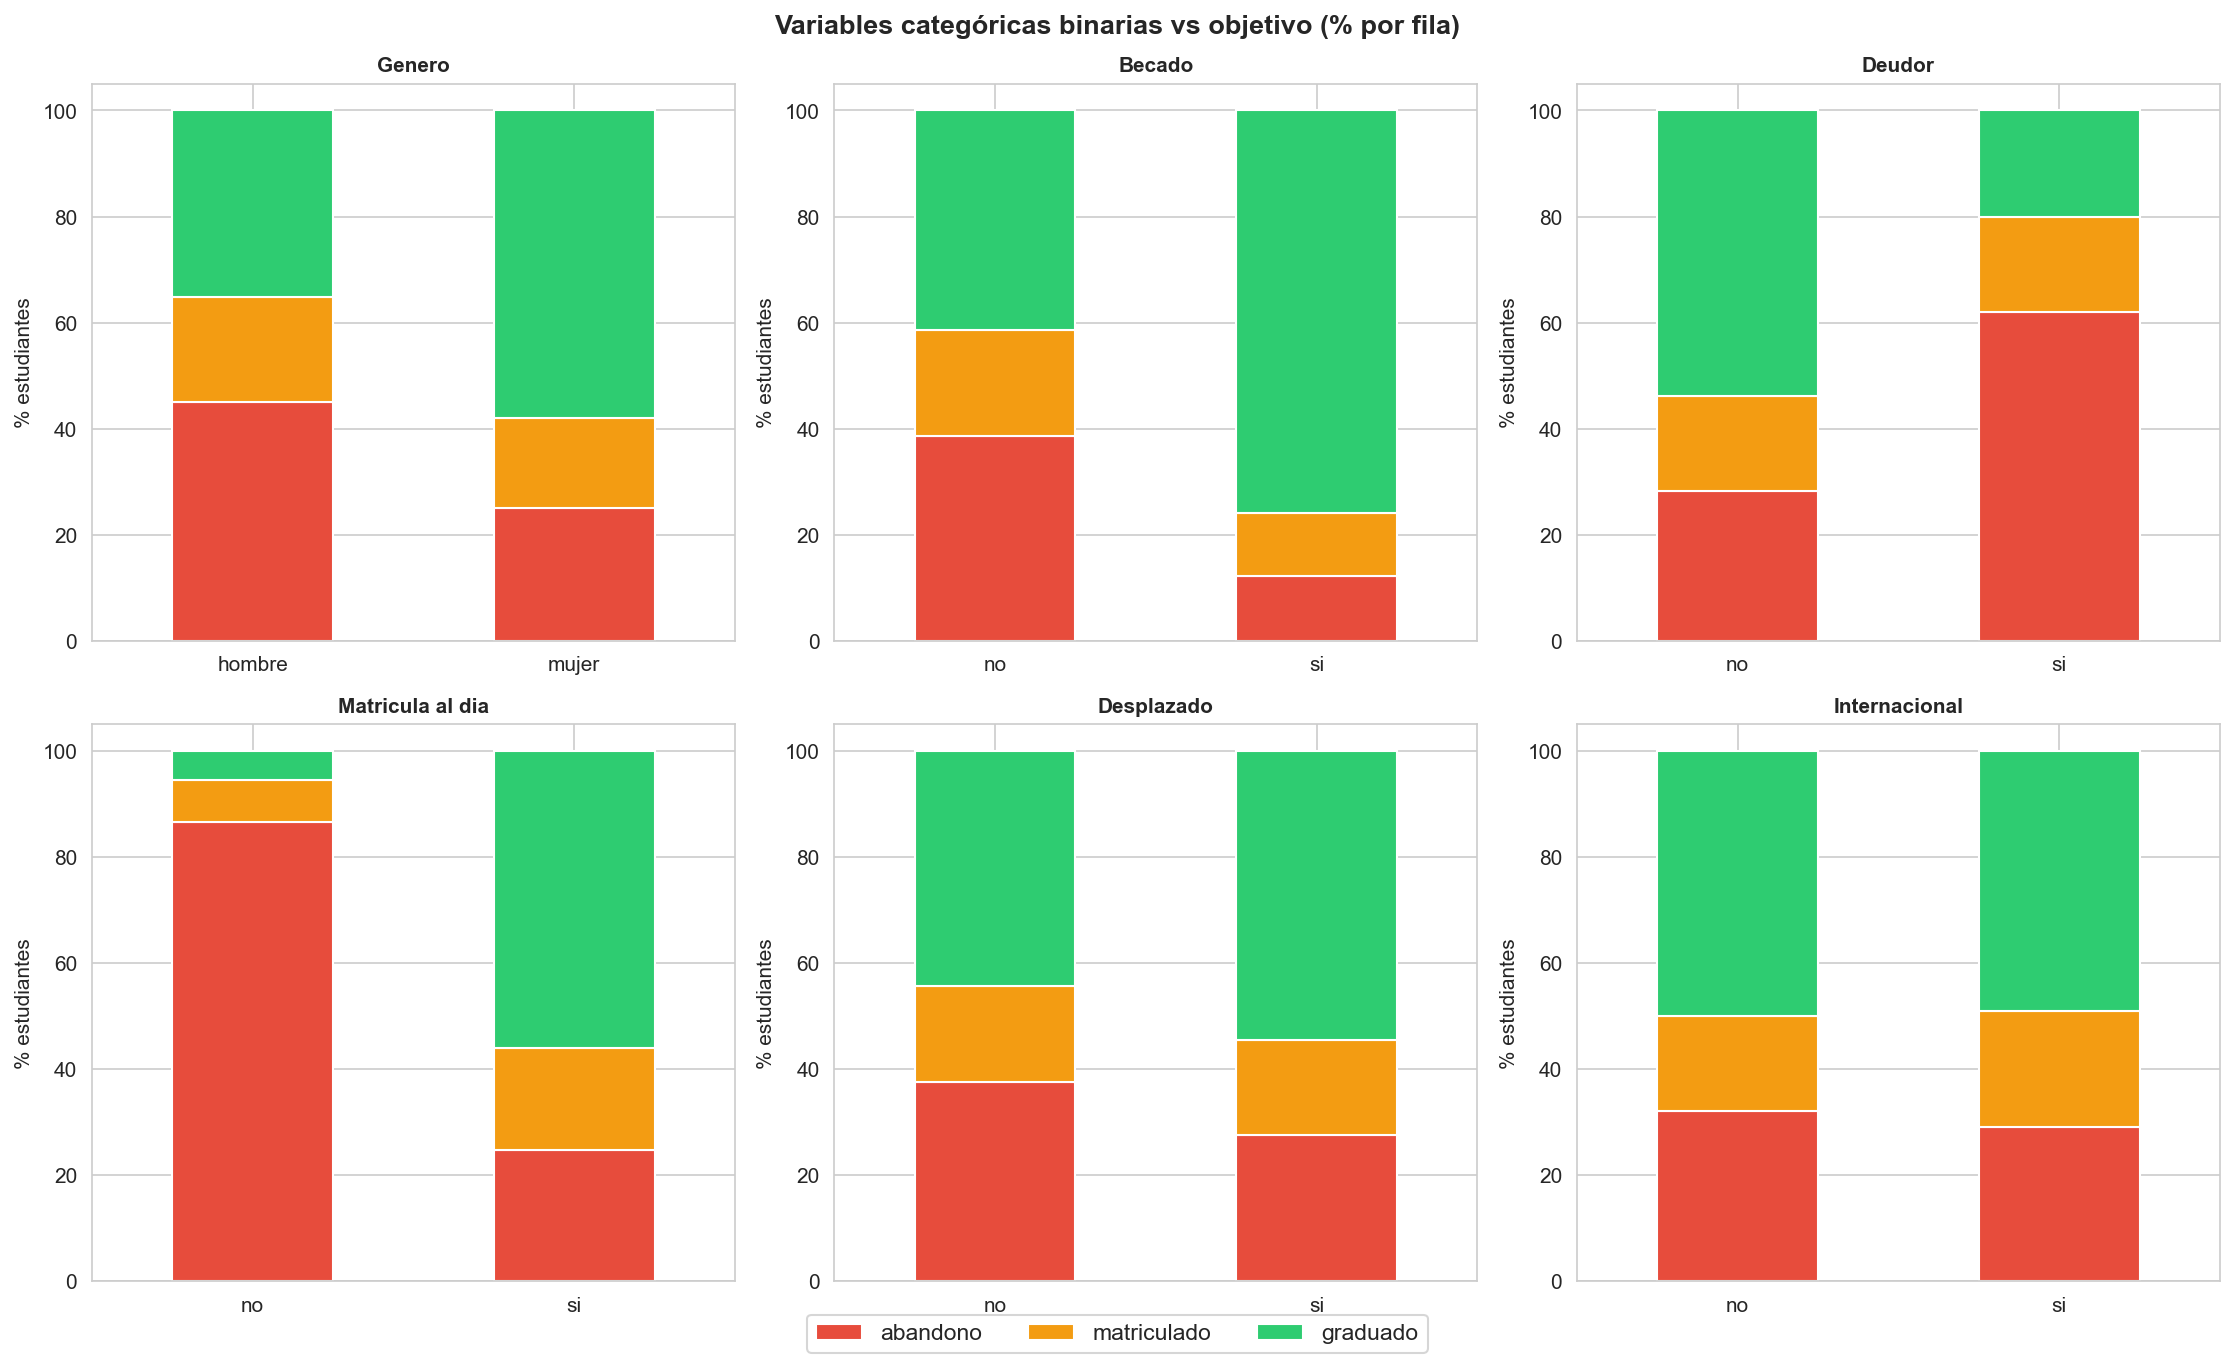

In [16]:
bin_cats = ['genero', 'becado', 'deudor', 'matricula_al_dia', 'desplazado', 'internacional']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, var in enumerate(bin_cats):
    ct = pd.crosstab(df[var], df['objetivo'], normalize='index')[ORDEN] * 100   # porcentaje por fila
    ct.plot(kind='bar', stacked=True, color=[COLORES[c] for c in ORDEN], ax=axes[i],
            legend=False, edgecolor='white')
    axes[i].set_title(var.replace('_', ' ').capitalize(), fontweight='bold', fontsize=10)
    axes[i].set_ylabel('% estudiantes')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=0)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, -0.02))
plt.suptitle('Variables categóricas binarias vs objetivo (% por fila)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()


In [17]:
# - hombres abandonan más
# - becados se gradúan más
# - deudores abandonan más
# - matricula al día se asocia a graduación
# - desplazado e internacional muestran diferencias más pequeñas
# (son asociaciones, no causas)
for var in bin_cats:
    ct = pd.crosstab(df[var], df['objetivo'], normalize='index')[ORDEN] * 100
    print(f'\n{var.upper()}:')
    print(ct.round(1).to_string())


GENERO:
objetivo  abandono  matriculado  graduado
genero                                   
hombre        45.1         19.7      35.2
mujer         25.1         17.0      57.9

BECADO:
objetivo  abandono  matriculado  graduado
becado                                   
no            38.7         20.0      41.3
si            12.2         11.8      76.0

DEUDOR:
objetivo  abandono  matriculado  graduado
deudor                                   
no            28.3         18.0      53.8
si            62.0         17.9      20.1

MATRICULA_AL_DIA:
objetivo          abandono  matriculado  graduado
matricula_al_dia                                 
no                    86.6          8.0       5.5
si                    24.7         19.3      56.0

DESPLAZADO:
objetivo    abandono  matriculado  graduado
desplazado                                 
no              37.6         18.1      44.3
si              27.6         17.8      54.6

INTERNACIONAL:
objetivo       abandono  matriculado  graduad

### 7.1. Cramér's V para el resto de categóricas

Las binarias ya las he mirado. Para el resto (`curso`, `nacionalidad`, `cualificacion_previa`, `estado_civil`, `ocupacion_*`...) uso Cramér's V, que da un número entre 0 y 1 (0 = independencia, 1 = asociación perfecta).

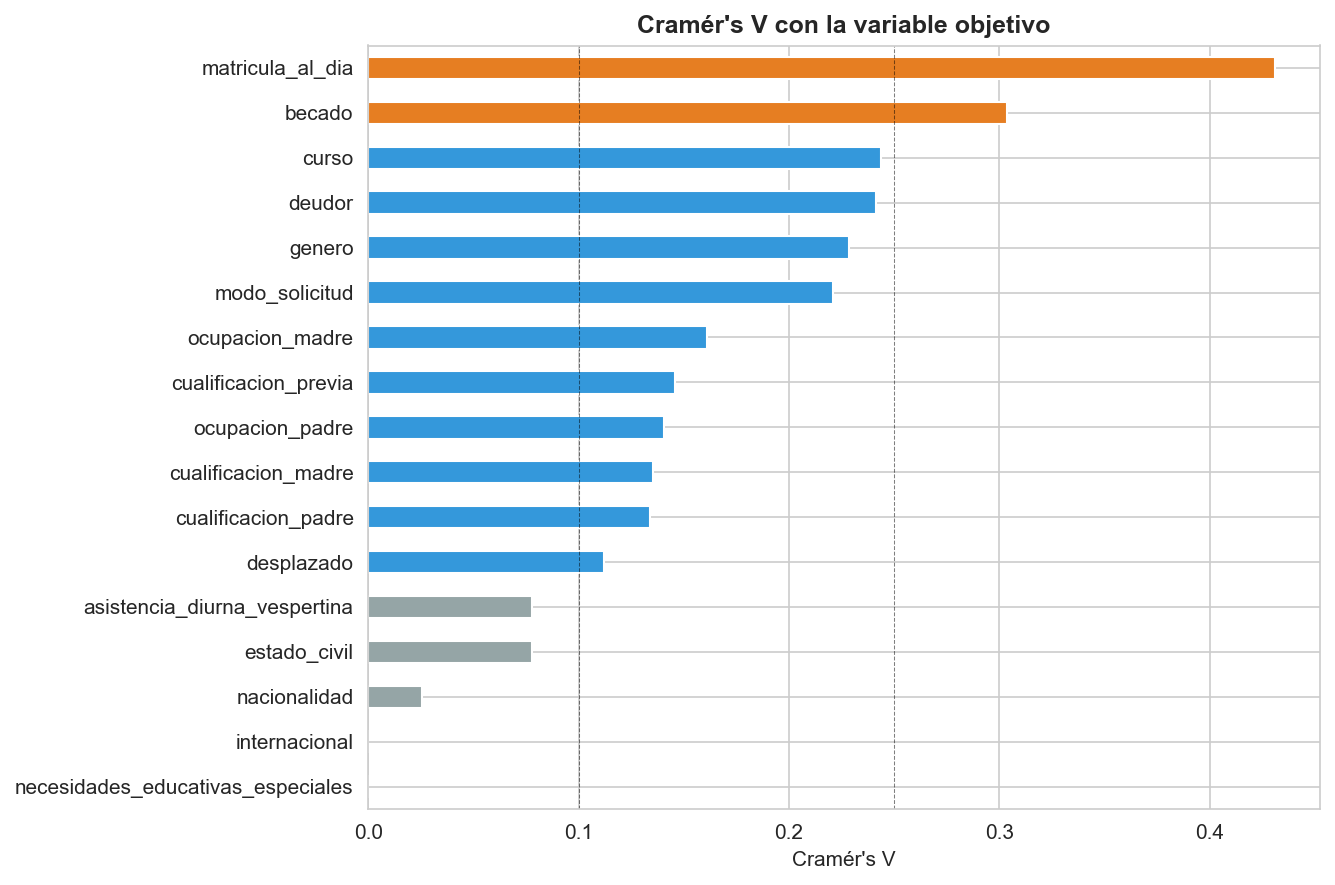

matricula_al_dia                     0.431
becado                               0.304
curso                                0.244
deudor                               0.241
genero                               0.229
modo_solicitud                       0.221
ocupacion_madre                      0.161
cualificacion_previa                 0.146
ocupacion_padre                      0.140
cualificacion_madre                  0.135
cualificacion_padre                  0.134
desplazado                           0.112
asistencia_diurna_vespertina         0.078
estado_civil                         0.078
nacionalidad                         0.026
necesidades_educativas_especiales    0.000
internacional                        0.000


In [18]:
# Cramér's V entre cada categórica y el objetivo
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    # corrección de sesgo para muestras pequeñas / tablas grandes
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(kcorr - 1, rcorr - 1)
    return np.sqrt(phi2corr / denom) if denom > 0 else 0.0

cv = {var: cramers_v(df[var], df['objetivo']) for var in cat_cols}
cv_series = pd.Series(cv).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#95a5a6' if v < 0.1 else ('#3498db' if v < 0.25 else '#e67e22') for v in cv_series.values]
cv_series.plot(kind='barh', color=colors, ax=ax)
ax.set_title("Cramér's V con la variable objetivo", fontweight='bold')
ax.set_xlabel("Cramér's V")
ax.axvline(0.1, color='black', linewidth=0.5, linestyle='--', alpha=0.5)
ax.axvline(0.25, color='black', linewidth=0.5, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

print(cv_series.sort_values(ascending=False).round(3).to_string())
# referencia: <0.1 débil, 0.1-0.25 moderada, >0.25 fuerte

## 8. Asignaturas aprobadas por semestre

Probablemente una de las variables más informativas.

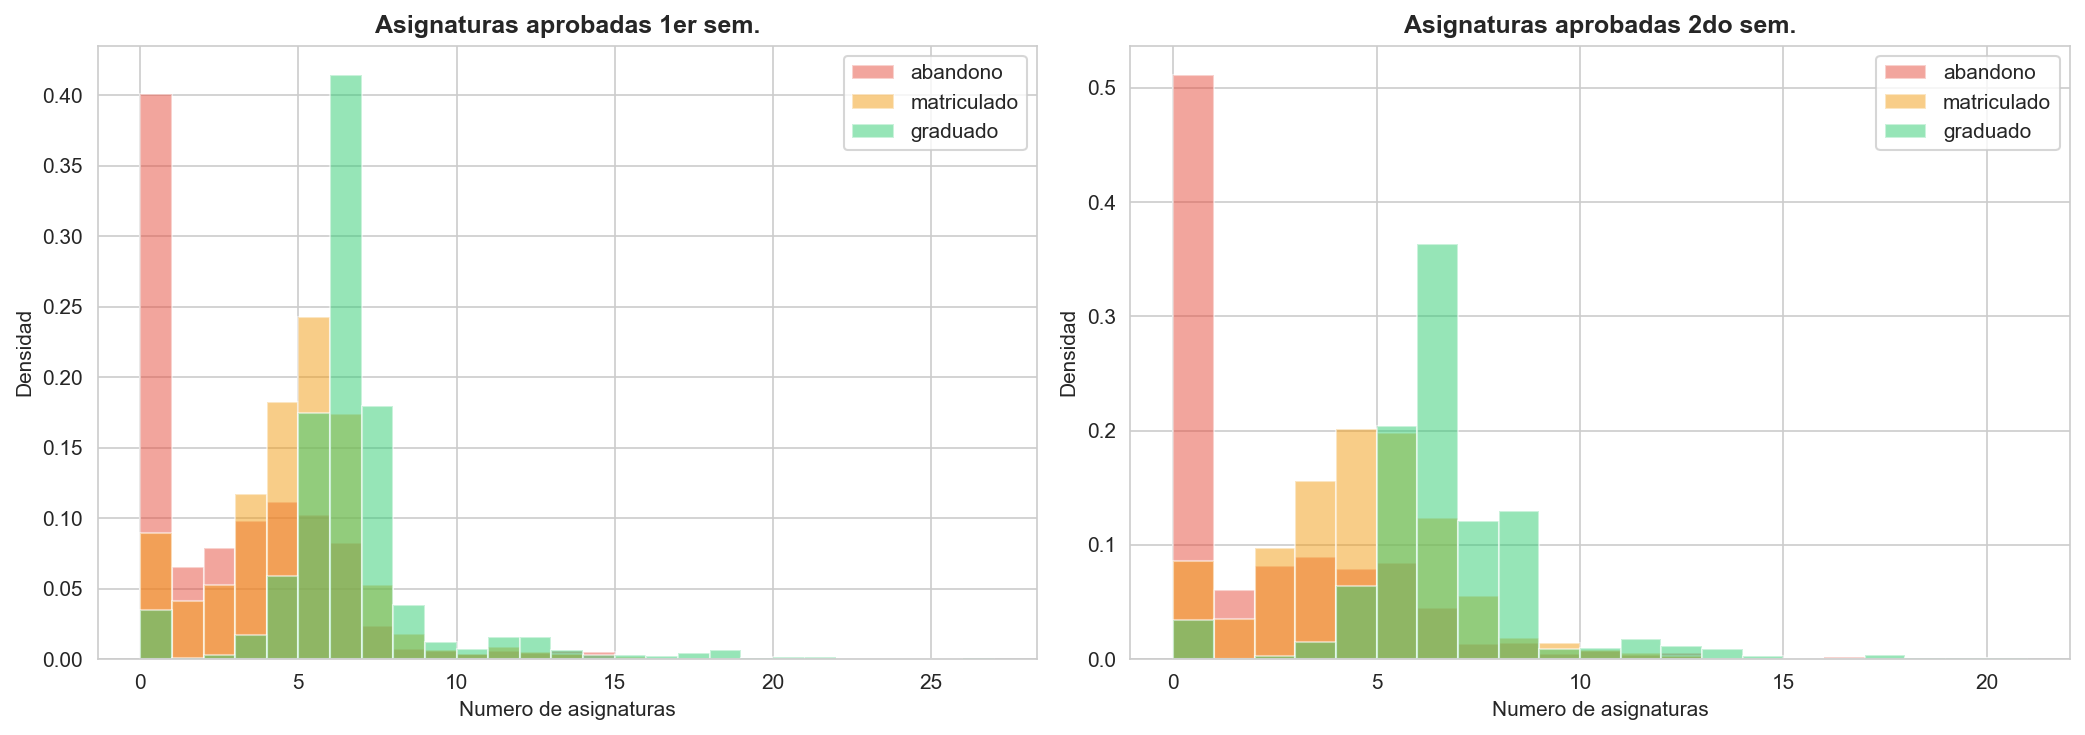

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, var, titulo in zip(axes,
    ['asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas'],
    ['Asignaturas aprobadas 1er sem.', 'Asignaturas aprobadas 2do sem.']):
    for cat in ORDEN:
        subset = df[df['objetivo'] == cat][var]
        ax.hist(subset, bins=range(0, int(df[var].max())+2), alpha=0.5,
                color=COLORES[cat], label=cat, density=True)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Numero de asignaturas')
    ax.set_ylabel('Densidad')
    ax.legend()

plt.tight_layout()
plt.show()


In [20]:
# los que abandonan aprueban muy pocas
# los graduados se concentran en 5-6 aprobadas
print("Media de asignaturas aprobadas por clase:")
for sem in ['1sem', '2sem']:
    var = f'asignaturas_{sem}_aprobadas'
    print(f"\n{var}:")
    print(df.groupby('objetivo')[var].mean().reindex(ORDEN).round(2).to_string())

Media de asignaturas aprobadas por clase:

asignaturas_1sem_aprobadas:
objetivo
abandono       2.55
matriculado    4.32
graduado       6.23

asignaturas_2sem_aprobadas:
objetivo
abandono       1.94
matriculado    4.06
graduado       6.18


## 9. Edad al matricularse


Rango de edades: 17 - 70


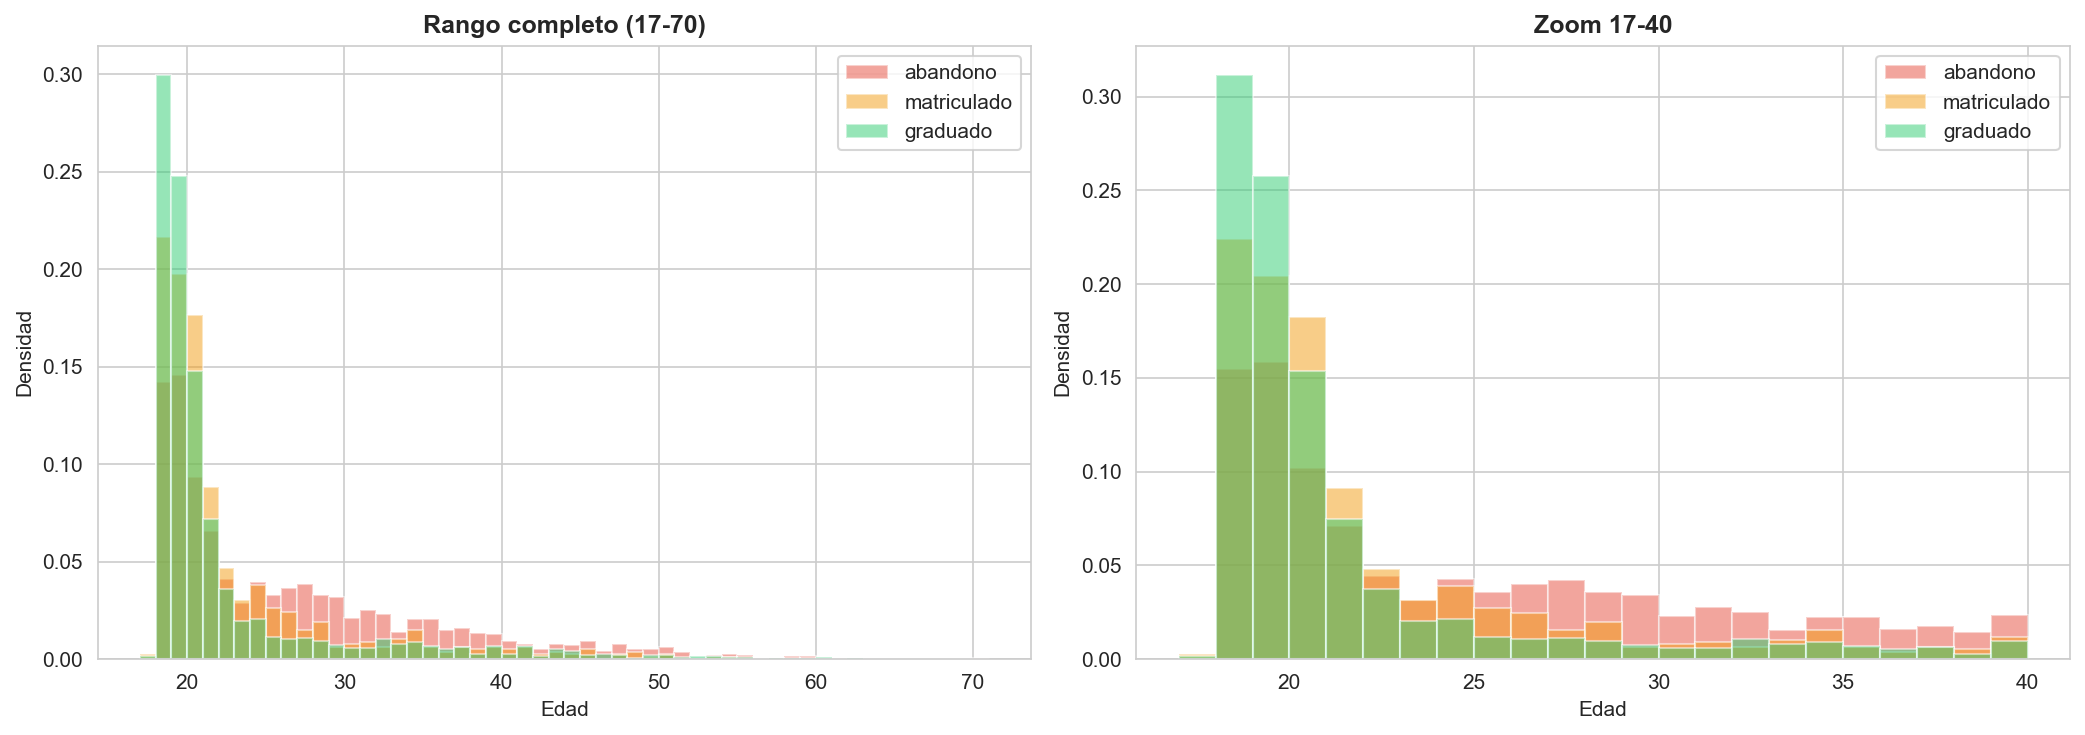


Edad media por clase:
objetivo
abandono       26.1
matriculado    22.4
graduado       21.8
Name: edad_al_matricularse, dtype: float64

Estudiantes con edad > 40: 225


In [21]:
# el rango real llega a ~70, así que pinto rango completo + un zoom al grueso
edad_min = int(df['edad_al_matricularse'].min())
edad_max = int(df['edad_al_matricularse'].max())
print(f'Rango de edades: {edad_min} - {edad_max}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# rango completo
for cat in ORDEN:
    subset = df[df['objetivo'] == cat]['edad_al_matricularse']
    axes[0].hist(subset, bins=range(edad_min, edad_max + 2),
                 alpha=0.5, color=COLORES[cat], label=cat, density=True)
axes[0].set_title(f'Rango completo ({edad_min}-{edad_max})', fontweight='bold')
axes[0].set_xlabel('Edad'); axes[0].set_ylabel('Densidad'); axes[0].legend()

# zoom al grueso de la distribución
for cat in ORDEN:
    subset = df[df['objetivo'] == cat]['edad_al_matricularse']
    axes[1].hist(subset, bins=range(17, 41),
                 alpha=0.5, color=COLORES[cat], label=cat, density=True)
axes[1].set_title('Zoom 17-40', fontweight='bold')
axes[1].set_xlabel('Edad'); axes[1].set_ylabel('Densidad'); axes[1].legend()

plt.tight_layout(); plt.show()

# los más jóvenes (17-20) se gradúan más, los que entran mayores abandonan más
print('\nEdad media por clase:')
print(df.groupby('objetivo')['edad_al_matricularse'].mean().reindex(ORDEN).round(1))
print(f"\nEstudiantes con edad > 40: {(df['edad_al_matricularse'] > 40).sum()}")

## 10. Tasas de abandono por curso

Cada titulación tiene tasas de abandono muy diferentes. Esto puede ser importante como feature.


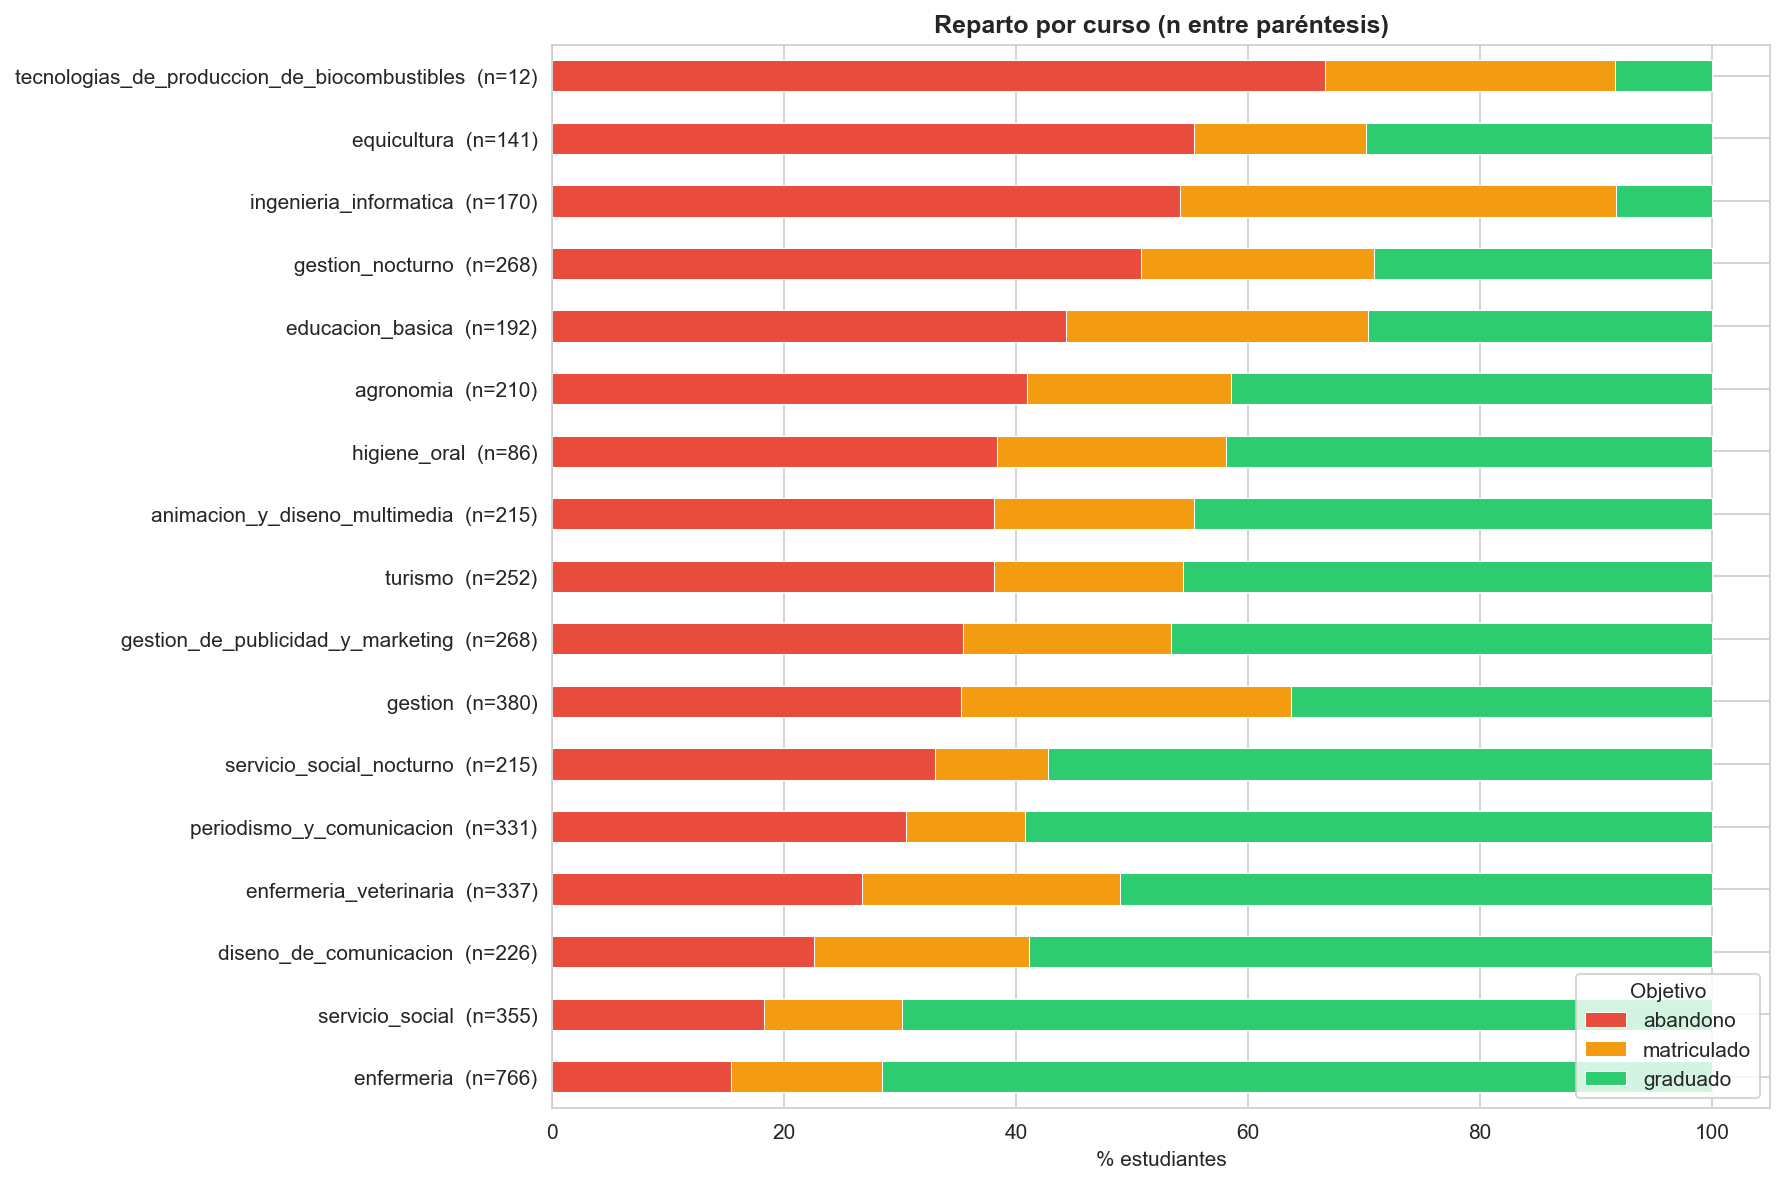


Tamaño muestral por curso:
curso
enfermeria                                      766
gestion                                         380
servicio_social                                 355
enfermeria_veterinaria                          337
periodismo_y_comunicacion                       331
gestion_de_publicidad_y_marketing               268
gestion_nocturno                                268
turismo                                         252
diseno_de_comunicacion                          226
animacion_y_diseno_multimedia                   215
servicio_social_nocturno                        215
agronomia                                       210
educacion_basica                                192
ingenieria_informatica                          170
equicultura                                     141
higiene_oral                                     86
tecnologias_de_produccion_de_biocombustibles     12


In [22]:
# añado el n al lado del curso, si no los % con pocos alumnos engañan
curso_obj = pd.crosstab(df['curso'], df['objetivo'], normalize='index')[ORDEN] * 100
curso_n   = df['curso'].value_counts()
curso_obj = curso_obj.sort_values('abandono', ascending=True)
curso_n   = curso_n.reindex(curso_obj.index)

etiquetas = [f'{c}  (n={int(curso_n[c])})' for c in curso_obj.index]

fig, ax = plt.subplots(figsize=(12, 8))
curso_obj.plot(kind='barh', stacked=True, color=[COLORES[c] for c in ORDEN],
               ax=ax, edgecolor='white', linewidth=0.5)
ax.set_yticklabels(etiquetas)
ax.set_title('Reparto por curso (n entre paréntesis)', fontweight='bold', fontsize=12)
ax.set_xlabel('% estudiantes'); ax.set_ylabel('')
ax.legend(title='Objetivo', loc='lower right')
plt.tight_layout(); plt.show()

print('\nTamaño muestral por curso:')
print(df['curso'].value_counts().to_string())

## 11. Correlación de cada numérica con cada clase

Point-biserial de cada numérica frente a cada clase (pasada a binaria).

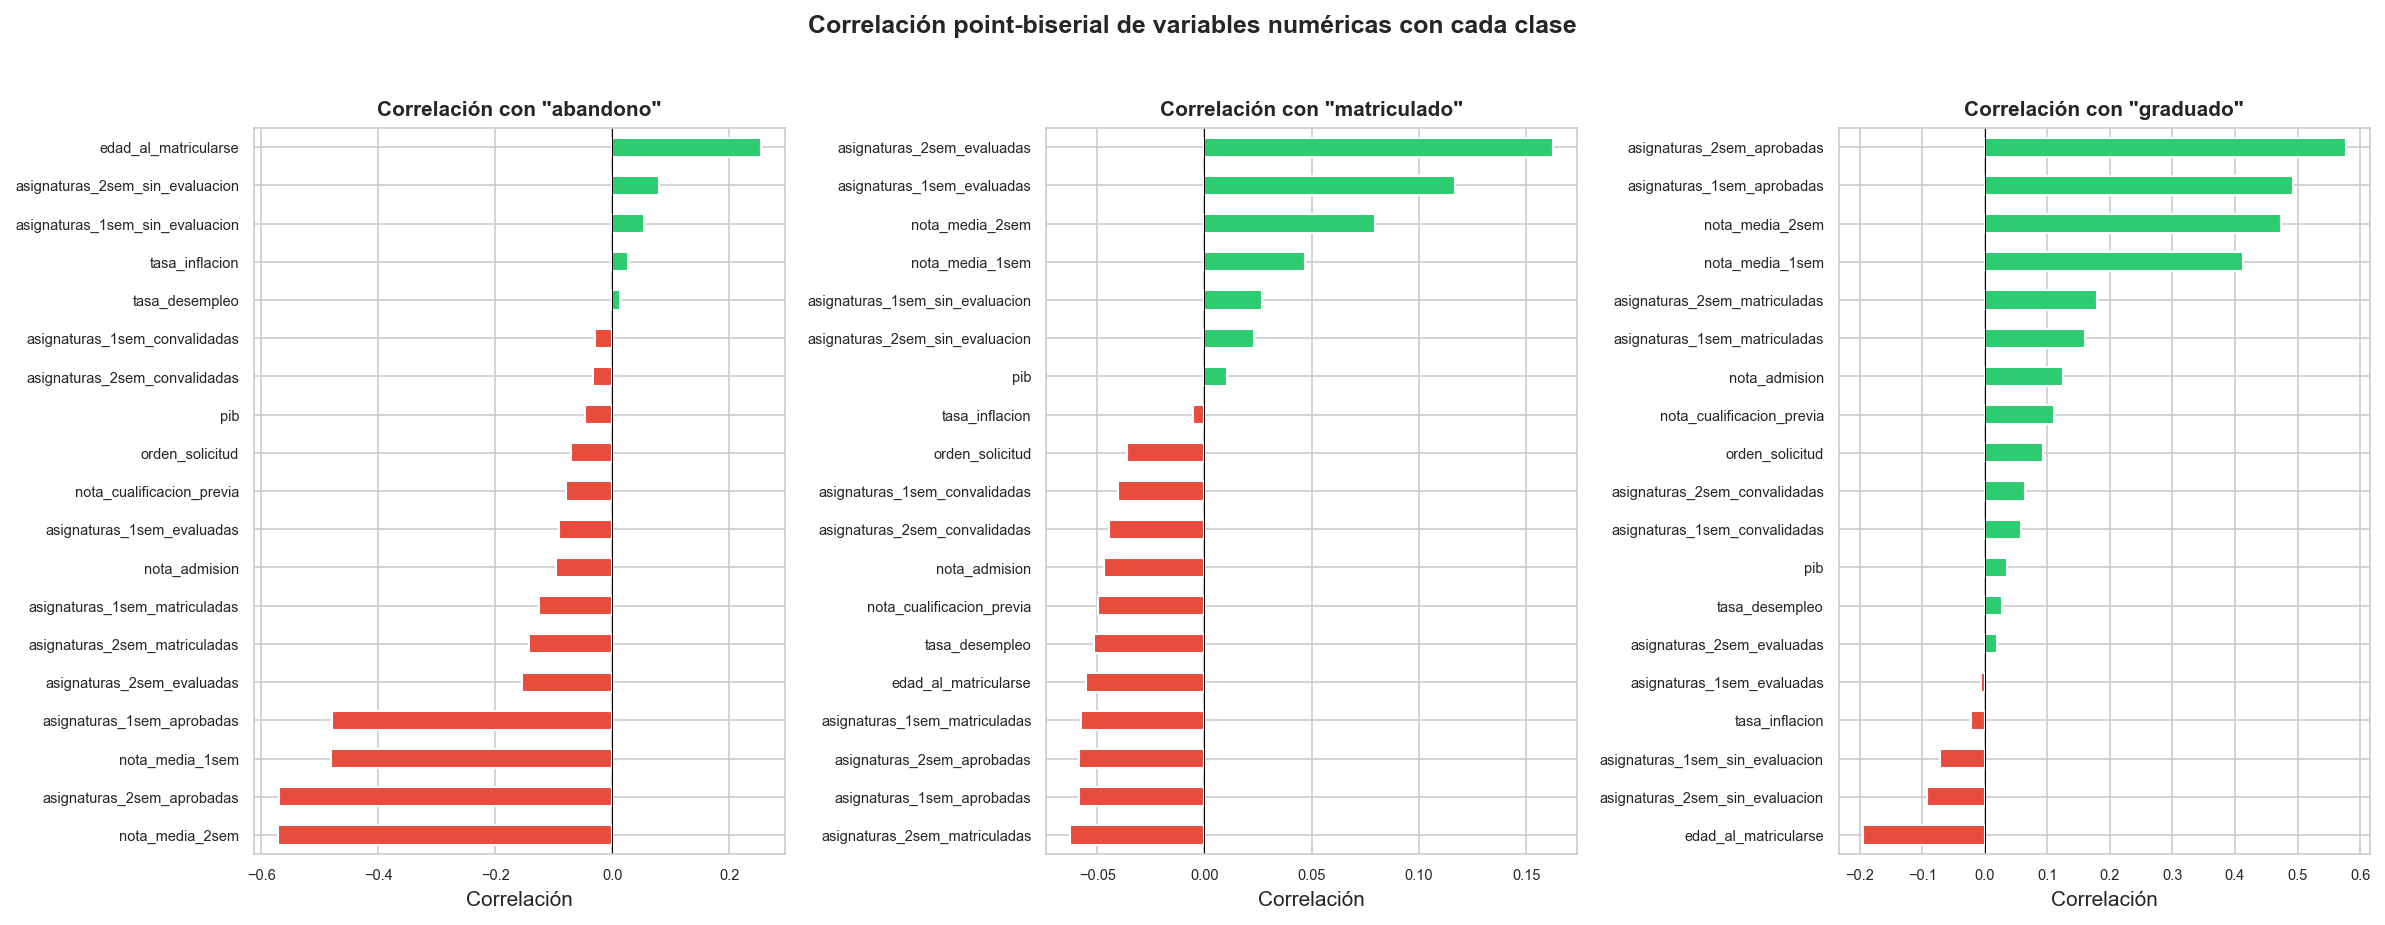

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax_idx, target_class in enumerate(ORDEN):
    binary = (df['objetivo'] == target_class).astype(int)
    correlations = df[num_cols].corrwith(binary).sort_values()
    
    colors_bar = ['#e74c3c' if v < 0 else '#2ecc71' for v in correlations.values]
    correlations.plot(kind='barh', color=colors_bar, ax=axes[ax_idx])
    axes[ax_idx].set_title(f'Correlación con "{target_class}"', fontweight='bold', fontsize=10)
    axes[ax_idx].set_xlabel('Correlación')
    axes[ax_idx].axvline(x=0, color='black', linewidth=0.5)
    axes[ax_idx].tick_params(labelsize=7)

plt.suptitle('Correlación point-biserial de variables numéricas con cada clase',
             fontweight='bold', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 12. Pairplot de variables clave

Relaciones 2 a 2 de las variables más importantes, coloreado por clase.

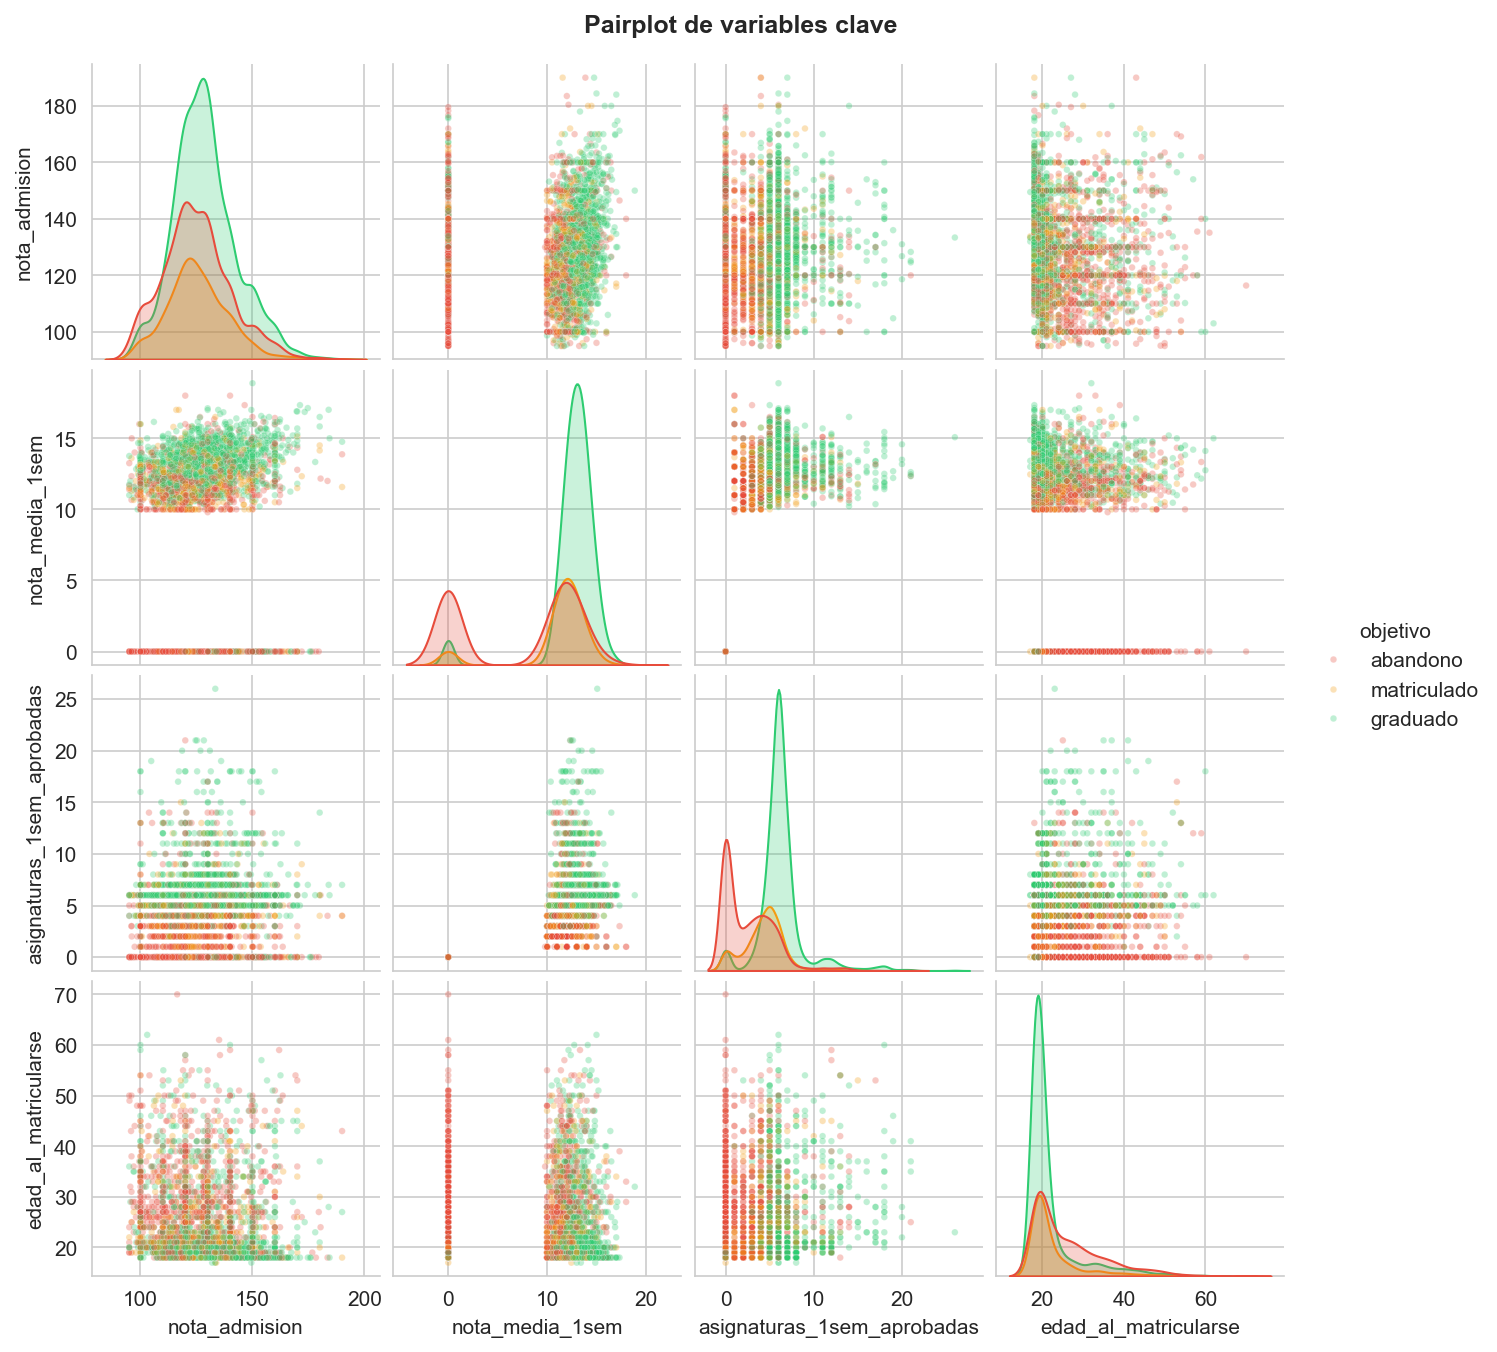

In [24]:
vars_pair = ['nota_admision', 'nota_media_1sem', 'asignaturas_1sem_aprobadas',
             'edad_al_matricularse', 'objetivo']

g = sns.pairplot(df[vars_pair], hue='objetivo', hue_order=ORDEN, palette=COLORES,
                 diag_kind='kde', plot_kws={'alpha': 0.3, 's': 10}, height=2.2)
g.figure.suptitle('Pairplot de variables clave', fontweight='bold', y=1.02)
plt.show()

## 13. Conclusiones del EDA

El dataset son 4.424 estudiantes con 37 variables, todas rellenas y sin duplicados. Las 36 predictoras las organizo en seis bloques (demográficas, acceso, socioeconómicas, macro, 1er sem, 2º sem) y mantengo esa misma agrupación en los notebooks siguientes para que sea fácil de seguir.

Sobre el desbalanceo, las clases salen graduado 49,9 %, abandono 32,1 % y matriculado 17,9 %. No es extremo pero sí suficiente como para que la métrica importe: el baseline trivial saca accuracy ~ 0,50 y F1 macro ~ 0,22, así que en clasificación me voy a apoyar en F1 macro.

Lo que más separa las clases ya se intuye en los gráficos. Las asignaturas aprobadas en cualquiera de los dos semestres son la señal más fuerte (los que abandonan se acumulan en 0). Las notas medias también discriminan, y entre las dos correlacionan ~0,84, lo cual va a ser el motor de la regresión del 2º semestre. Las administrativas (deudor, matrícula al día, beca) marcan diferencias visibles. Y la edad: los jóvenes de 17-20 se gradúan más y los que entran mayores abandonan bastante más. Insisto en que son asociaciones en la muestra, no causas.

Las tasas por titulación son muy diferentes (algunos cursos rondan el 50 % de abandono y otros se quedan en el 15 %), pero los de n bajo conviene leerlos con cautela. Las macroeconómicas (desempleo, inflación, PIB) correlacionan poco con el rendimiento individual; las dejo como contexto pero sin sobrevalorarlas.

Para los demás notebooks me llevo tres cosas. En la regresión sobre `nota_media_2sem` excluyo las otras variables del 2º semestre por leakage. En clasificación las uso todas, pero si el modelo se apoya mucho en el 2º sem no lo vendo como detección temprana. Y para el clustering del notebook 04, las correlaciones y la Cramér's V me dan la base para razonar el subconjunto de variables.